# Tracking aperture losses

In this notebook we turn the interpolated aperture from notebook 002 into
tracking elements, launch a beam with a controlled halo, and track it around
the ring. This is a deliberately constructed demonstration: the halo is
chosen to produce visible losses, not to represent a measured beam.

We restore the aperture definitions and placements with `env.aperture.from_json`, then
build `ring.aperture` before sampling the geometry for tracking limits.

The sequence is: install aperture limits, generate and track particles,
locate losses, then inspect them along the ring and in transverse/3D views.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xtrack as xt

data_dir = Path.cwd()
env = xt.load(data_dir / "toy_ring.json")
ring = env["ring"]
# Keep a clean optics line for aperture queries and a separate copy for
# inserting the discrete tracking limits.
tracking_env = xt.load(data_dir / "toy_ring.json")
tracking_ring = tracking_env["ring"]
env.aperture.from_json(data_dir / "aperture_model.json")
model = ring.aperture
model.build_model()
length = ring.get_length()
twiss = ring.twiss()

print(f"Ring circumference: {length:.2f} m")
print(f"Tunes: Qx = {twiss.qx:.3f}, Qy = {twiss.qy:.3f}")
print(
    "Horizontal dispersion range: "
    f"{np.min(twiss.dx):.1f} to {np.max(twiss.dx):.1f} m"
)

Loading line from dict:   0%|          | 0/84 [00:00<?, ?it/s]

Done loading line from dict.           
Done loading line from dict.           


Loading line from dict:   0%|          | 0/84 [00:00<?, ?it/s]

Done loading line from dict.           
Done loading line from dict.           


Building cross-sections:   0%|          | 0/244 [00:00<?, ?it/s]

Ring circumference: 104.26 m
Tunes: Qx = 0.594, Qy = 2.775
Horizontal dispersion range: 39.6 to 54.4 m


## Install aperture limits

`get_limit_elements_at_s` samples the interpolated aperture and returns ordinary
Xtrack `LimitPolygon` elements. We install one at each sampled longitudinal
position. The one-metre sampling gives a useful first loss map; it also
means the recorded loss locations are quantized to this mesh. A finer mesh
can be used when investigating one particular region.

In [2]:
sample_s = np.arange(0.5, length, 1.0)
# The ring is periodic: omit the duplicate start/end limits and avoid
# inserting a limit exactly at the injection point.
sample_s = sample_s[(sample_s > 1e-4) & (sample_s < length - 1e-4)]
# The profile interpolation helper emits a progress bar for every sampled
# section; keep that internal chatter out of the notebook output.
limit_elements = model.get_limit_elements_at_s(sample_s)

limit_s_by_name = {}
for idx, (s, element) in enumerate(limit_elements.items()):
    name = f"loss_limit_{idx:04d}"
    tracking_ring.insert(
        what=name, obj=element, at=float(s), anchor="start", with_progress=False
    )
    limit_s_by_name[name] = float(s)

tracking_ring.build_tracker()
print(f"Installed {len(limit_s_by_name)} aperture limits around the ring.")

Installed 104 aperture limits around the ring.


## Generate a beam with a visible halo

The core is Gaussian in normalized transverse phase space. A fraction of
particles is placed in a 5–14 sigma halo, with randomized betatron phase in
both planes. A small momentum spread adds a dispersive contribution. The
distribution is matched to the current linear Twiss optics at the ring
start; the halo fraction, emittances, and momentum spread are demo knobs.

In [3]:
rng = np.random.default_rng(20260923)
num_particles = 4000
halo_fraction = 0.18
halo_max_sigma = 14.0
nemitt_x = 3.5e-6
nemitt_y = 3.5e-6
delta_rms = 1.0e-4

x_norm = rng.normal(size=num_particles)
px_norm = rng.normal(size=num_particles)
y_norm = rng.normal(size=num_particles)
py_norm = rng.normal(size=num_particles)

halo_x = rng.random(num_particles) < halo_fraction
halo_y = rng.random(num_particles) < halo_fraction
for mask, q, p in ((halo_x, x_norm, px_norm), (halo_y, y_norm, py_norm)):
    radius = rng.uniform(5.0, halo_max_sigma, mask.sum())
    phase = rng.uniform(0.0, 2.0 * np.pi, mask.sum())
    q[mask] = radius * np.cos(phase)
    p[mask] = radius * np.sin(phase)

delta = rng.normal(0.0, delta_rms, num_particles)
particles = tracking_ring.build_particles(
    at_element=0,
    x_norm=x_norm,
    px_norm=px_norm,
    y_norm=y_norm,
    py_norm=py_norm,
    nemitt_x=nemitt_x,
    nemitt_y=nemitt_y,
    delta=delta,
)

print(
    f"Generated {num_particles:,} particles; "
    f"{halo_x.sum()} have horizontal halo amplitudes and "
    f"{halo_y.sum()} have vertical halo amplitudes."
)

Generated 4,000 particles; 727 have horizontal halo amplitudes and 728 have vertical halo amplitudes.


## Track one turn and locate the losses

For this first pass, one turn is enough: the aim is to see where the
injected halo first encounters the aperture, rather than model a long-term
loss process. Xtrack records the lost-particle state at the explicit limit
element that stopped the particle.

In [4]:
tracking_ring.track(particles, num_turns=1)
lost_mask = particles.state <= 0
lost_indices = np.flatnonzero(lost_mask)
element_names = np.asarray(tracking_ring.element_names, dtype=object)
loss_names = element_names[np.asarray(particles.at_element[lost_mask], dtype=int)]
loss_s = np.asarray([limit_s_by_name.get(name, np.nan) for name in loss_names])
valid = np.isfinite(loss_s)

losses = {
    "particle_id": np.asarray(particles.particle_id[lost_mask])[valid],
    "element": loss_names[valid],
    "s": loss_s[valid],
    "x": np.asarray(particles.x[lost_mask])[valid],
    "y": np.asarray(particles.y[lost_mask])[valid],
    "delta": np.asarray(particles.delta[lost_mask])[valid],
    "state": np.asarray(particles.state[lost_mask])[valid],
}

print(
    f"Lost {len(losses['s']):,} of {len(particles.particle_id):,} particles "
    f"({len(losses['s']) / len(particles.particle_id):.1%}) on the first turn."
)
print(f"Losses recorded at {len(np.unique(losses['element']))} distinct limits.")

Lost 938 of 4,000 particles (23.4%) on the first turn.
Losses recorded at 65 distinct limits.


## Where around the ring do particles hit?

The aperture/envelope extent plot gives the machine context. The histogram
beneath it shows how many tracked particles were stopped in each
one-metre bin. The loss positions are mesh locations, not continuous
impact coordinates.


Computing beam envelopes: 100%
Interpolating profiles: 100%

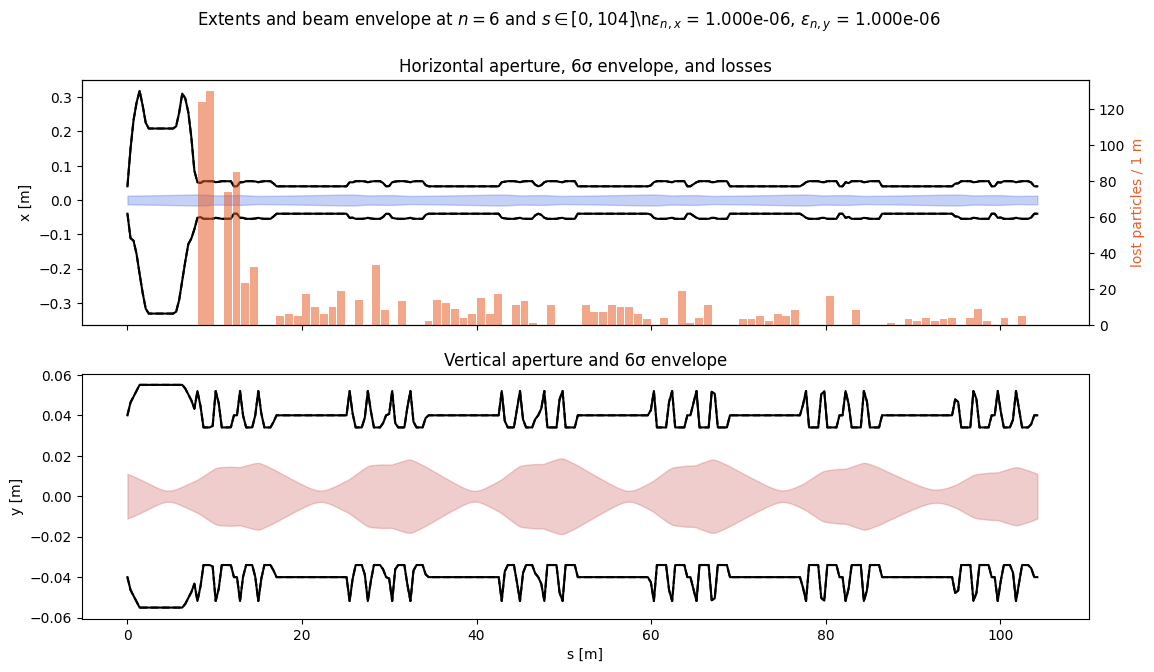

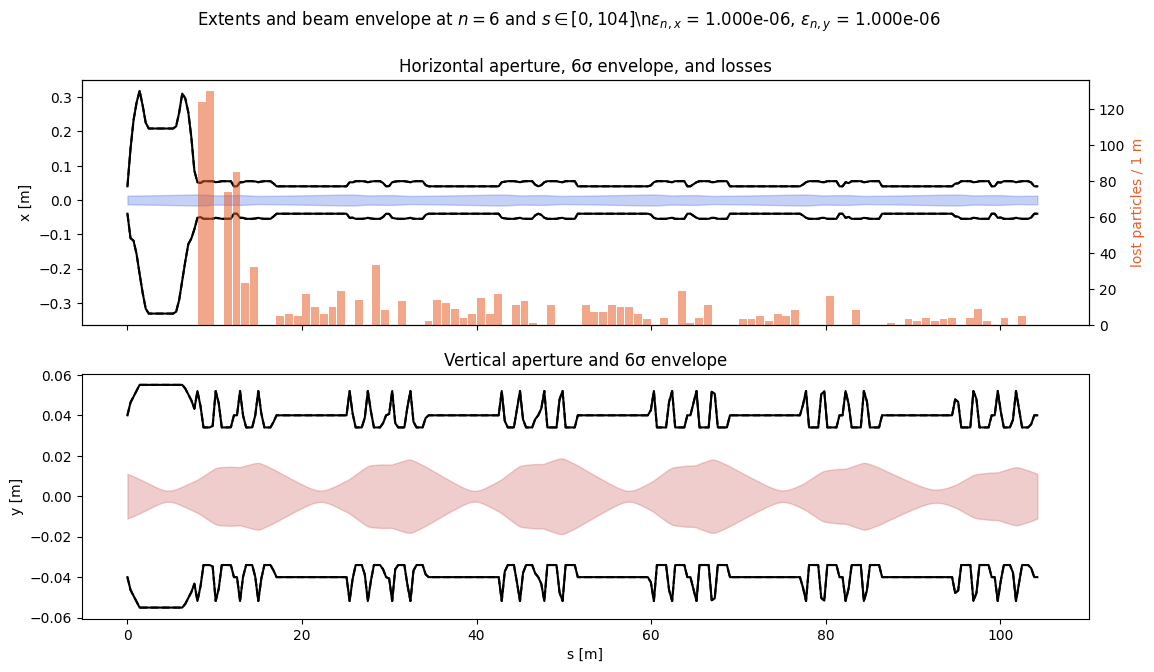

In [5]:
extent_s = np.linspace(0.0, length, 300)
extent_fig, extent_axes = model.plot_extents(
    s_positions=extent_s,
    sigmas=6.0,
    include_aper_tols=True,
    with_progress=False,
)
_bins = np.arange(0.0, length + 1.0, 1.0)
_counts, _edges = np.histogram(losses["s"], bins=_bins)
_centres = (_edges[:-1] + _edges[1:]) / 2
loss_count_ax = extent_axes[0].twinx()
loss_count_ax.bar(
    _centres, _counts, width=0.9, color="#e85d2a", alpha=0.55,
    label="lost particles / 1 m",
)
loss_count_ax.set_ylabel("lost particles / 1 m", color="#e85d2a")
extent_axes[0].set_title("Horizontal aperture, 6σ envelope, and losses")
extent_axes[0].set_ylabel("x [m]")
extent_axes[1].set_title("Vertical aperture and 6σ envelope")
extent_axes[1].set_ylabel("y [m]")
extent_axes[1].set_xlabel("s [m]")
extent_fig.set_size_inches(13, 7)
extent_fig

## Inspect one transverse cross-section

Choose the most populated loss station. The polygon is the installed
aperture section at that station; the points are particles stopped there,
in the local transverse coordinates used by the tracking element.


Interpolating profiles: 100%

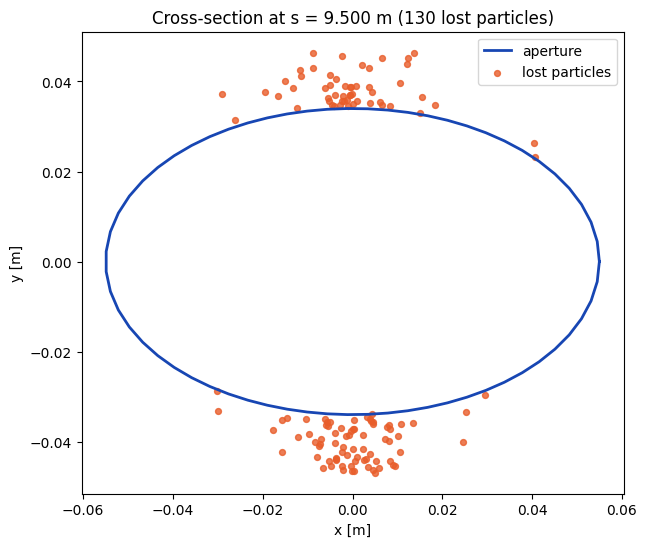

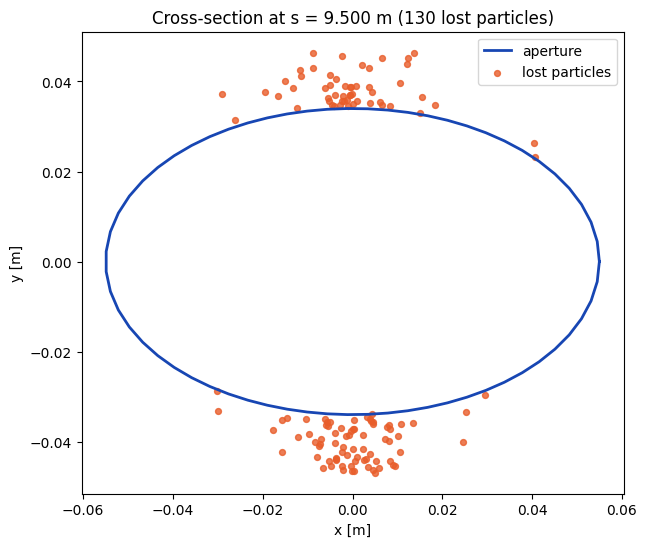

In [6]:
from contextlib import redirect_stderr as section_redirect_stderr
from contextlib import redirect_stdout as section_redirect_stdout
from io import StringIO as SectionStringIO

unique_s, counts = np.unique(losses["s"], return_counts=True)
focus_s = float(unique_s[np.argmax(counts)])
focus_mask = losses["s"] == focus_s
with section_redirect_stderr(SectionStringIO()), section_redirect_stdout(SectionStringIO()):
    section = model.get_cross_sections_at_s(np.asarray([focus_s]), extents=True)
polygon = section.cross_section[0]

section_fig, section_ax = plt.subplots(figsize=(7, 6))
section_ax.plot(polygon[:, 0], polygon[:, 1], color="#1746b3", lw=2, label="aperture")
section_ax.scatter(
    losses["x"][focus_mask], losses["y"][focus_mask],
    s=18, color="#e85d2a", alpha=0.8, label="lost particles",
)
section_ax.set_aspect("equal", adjustable="datalim")
section_ax.set_xlabel("x [m]")
section_ax.set_ylabel("y [m]")
section_ax.set_title(
    f"Cross-section at s = {focus_s:.3f} m "
    f"({focus_mask.sum()} lost particles)"
)
section_ax.legend()
section_fig

## Overlay impact points on the aperture in 3D

The selected short window is centred on the busiest loss station. Each
cross-section and impact point is transformed from its local beam frame to
the global survey frame using the aperture model's pose. The grey outlines
show the pipe; orange points show impacts. The view is intentionally local
so the chamber shape and loss locations remain visible.


Interpolating profiles: 100%
Interpolating profiles: 100%

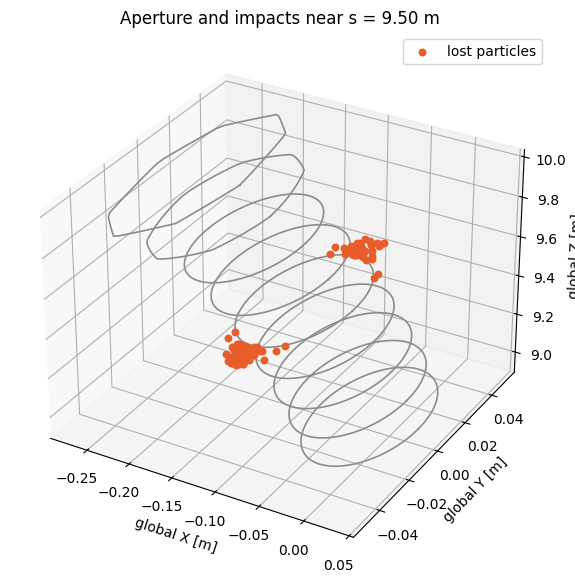

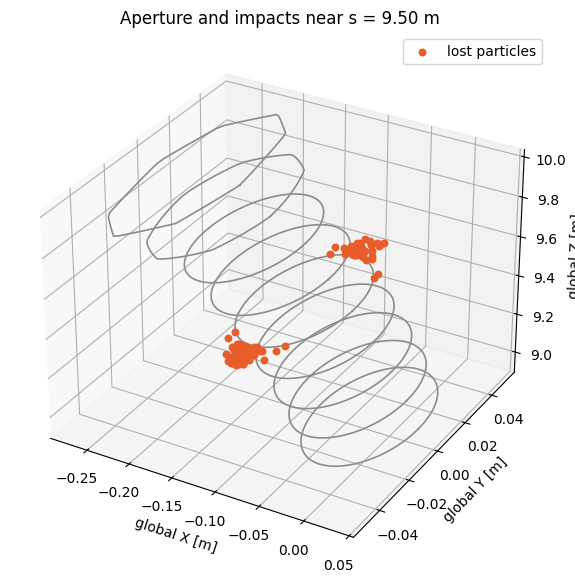

In [7]:
half_window = 0.5
window_s = np.linspace(
    max(0.0, focus_s - half_window),
    min(length, focus_s + half_window),
    9,
)
window_sections = model.get_cross_sections_at_s(window_s, extents=False)
in_window = np.abs(losses["s"] - focus_s) <= half_window

spatial_fig = plt.figure(figsize=(9, 7))
spatial_ax = spatial_fig.add_subplot(111, projection="3d")
for _row in window_sections.rows:
    _poly = _row.cross_section
    _local = np.column_stack((_poly[:, 0], _poly[:, 1], np.zeros(len(_poly)), np.ones(len(_poly))))
    _global = _local @ _row.pose.T
    spatial_ax.plot(_global[:, 0], _global[:, 1], _global[:, 2], color="0.55", lw=1.2)

_impact_s = losses["s"][in_window]
_unique_impact_s, _inverse = np.unique(_impact_s, return_inverse=True)
_impact_sections = model.get_cross_sections_at_s(_unique_impact_s, extents=False)
_impacts_xyz = []
_impact_x = losses["x"][in_window]
_impact_y = losses["y"][in_window]
for _i, _row in enumerate(_impact_sections.rows):
    _at_section = _inverse == _i
    _local_hits = np.column_stack((
        _impact_x[_at_section], _impact_y[_at_section],
        np.zeros(_at_section.sum()), np.ones(_at_section.sum()),
    ))
    _impacts_xyz.extend((_local_hits @ _row.pose.T)[:, :3])
if _impacts_xyz:
    _impacts_xyz = np.asarray(_impacts_xyz)
    spatial_ax.scatter(
        _impacts_xyz[:, 0], _impacts_xyz[:, 1], _impacts_xyz[:, 2],
        color="#e85d2a", s=22, depthshade=False, label="lost particles",
    )

spatial_ax.set_xlabel("global X [m]")
spatial_ax.set_ylabel("global Y [m]")
spatial_ax.set_zlabel("global Z [m]")
spatial_ax.set_title(f"Aperture and impacts near s = {focus_s:.2f} m")
spatial_ax.legend(loc="best")
spatial_fig